Credit Card Customers Segmentation

In [5]:
# Core data libraries
import numpy as np # numerical operations / ədədi hesablamalar üçün
import pandas as pd # dataframes (for tables) / cədvəl tipli məlumat üçün əsas kitabxana

# Visualization libraries
import matplotlib.pyplot as plt  # basic plotting / sadə qrafiklər çəkmək
import seaborn as sns # advanced statistical plots / statistik vizuallaşdırma

# Machine learning tools from scikit-learn
from sklearn.preprocessing import StandardScaler # scaling / məlumatı eyni miqyasa gətirmək
from sklearn.cluster import KMeans, AgglomerativeClustering # clustering algorithms / klasterləşdirmə alqoritmləri
from sklearn.metrics import silhouette_score, adjusted_rand_score # evaluate clusters / klasterlərin keyfiyyətini ölçmək

# Statistics and hierarchical tools
from scipy import stats # statistical functions / statistik funksiyalar
from scipy.cluster.hierarchy import dendrogram, linkage # dendrogram / dendroqram çəkmək üçün

# Random seed for reproducibility (ensures same results each run)
RANDOM_STATE = 42  # eyni nəticə üçün sabit təsadüfi başlanğıc

# Plot appearance settings
plt.rcParams['figure.figsize'] = (10,5) # default figure size / qrafik ölçüsü
plt.rcParams['font.size'] = 12 # font size / şrift ölçüsü

Step 1: Data Loading and Understanding

1.1 Load the dataset using pandas

In [9]:
# Load dataset from local Excel file (xls format, so we use read_excel instead of read_csv)
df = pd.read_csv("CC GENERAL.csv")

1.2 Display the first 10 rows

In [10]:
# View the first 10 rows — always a good first step in EDA
print("First 10 rows of the dataset / Datasetin ilk 10 sətri:")
display(df.head(10))

First 10 rows of the dataset / Datasetin ilk 10 sətri:


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
5,C10006,1809.828751,1.000000,1333.28,0.00,1333.28,0.000000,0.666667,0.000000,0.583333,0.000000,0,8,1800.0,1400.057770,2407.246035,0.000000,12
6,C10007,627.260806,1.000000,7091.01,6402.63,688.38,0.000000,1.000000,1.000000,1.000000,0.000000,0,64,13500.0,6354.314328,198.065894,1.000000,12
7,C10008,1823.652743,1.000000,436.20,0.00,436.20,0.000000,1.000000,0.000000,1.000000,0.000000,0,12,2300.0,679.065082,532.033990,0.000000,12
8,C10009,1014.926473,1.000000,861.49,661.49,200.00,0.000000,0.333333,0.083333,0.250000,0.000000,0,5,7000.0,688.278568,311.963409,0.000000,12
9,C10010,152.225975,0.545455,1281.60,1281.60,0.00,0.000000,0.166667,0.166667,0.000000,0.000000,0,3,11000.0,1164.770591,100.302262,0.000000,12


1.3 Print dataset shape

In [11]:
# Show how many rows/columns the dataset has
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (8950, 18)


1.4 Display column names and data types

In [12]:
# Column names
print("Column names:")
print(df.columns.tolist())

# Get information about column types and non-null counts
print("\n--- Info ---")
df.info()

Column names:
['CUST_ID', 'BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE      

1.5 Check for missing values

In [13]:
# Missing values per column
print("Missing values per column:")
display(df.isna().sum())

Missing values per column:


CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

Step 2: Data Cleaning and Preparation

2.1 Check for duplicate rows

In [14]:
# Count fully duplicated rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

# CUST_ID should be unique for every customer, so check it too
print("Number of duplicate CUST_ID:", df['CUST_ID'].duplicated().sum())

# Drop duplicates (if any)
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)

Number of duplicate rows: 0
Number of duplicate CUST_ID: 0
Shape after dropping duplicates: (8950, 18)


2.2 Handle missing values (if any)

In [15]:
# Copy dataframe so the original stays the same
df_clean = df.copy()

# Numeric columns with missing values: fill with median (median is not affected by outliers)
for col in ['MINIMUM_PAYMENTS', 'CREDIT_LIMIT']:
    median_value = df_clean[col].median()
    print(f"Median of {col}: {median_value}")
    df_clean[col] = df_clean[col].fillna(median_value)

print("\nRemaining missing values (should be 0):")
display(df_clean.isna().sum())

Median of MINIMUM_PAYMENTS: 312.343947
Median of CREDIT_LIMIT: 3000.0

Remaining missing values (should be 0):


CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

2.3 Select numerical features

In [16]:
# Select numeric columns (CUST_ID is text, so it is not included)
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
print("Numeric columns detected:", numeric_cols)

# Features that we use for clustering (from the lab description)
feature_cols = ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES',
                'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY',
                'CASH_ADVANCE_FREQUENCY', 'CREDIT_LIMIT', 'PAYMENTS',
                'MINIMUM_PAYMENTS', 'TENURE']

X = df_clean[feature_cols].copy()
print("\nFeature matrix shape:", X.shape)

Numeric columns detected: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']

Feature matrix shape: (8950, 12)


2.4 Normalize features using StandardScaler

In [17]:
# K-Means and hierarchical clustering use distance, so features must be on the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Put it back into a dataframe so it is easier to read
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
display(X_scaled_df.head())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,TENURE
0,-0.731989,-0.249434,-0.424900,-0.356934,-0.349079,-0.466786,-0.806490,-0.675349,-0.960378,-0.528979,-0.302400,0.36068
1,0.786961,0.134325,-0.469552,-0.356934,-0.454576,2.605605,-1.221758,0.573963,0.688678,0.818642,0.097500,0.36068
2,0.447135,0.518084,-0.107668,0.108889,-0.454576,-0.466786,1.269843,-0.675349,0.826100,-0.383805,-0.093293,0.36068
3,0.049099,-1.016953,0.232058,0.546189,-0.454576,-0.368653,-1.014125,-0.258913,0.826100,-0.598688,-0.228307,0.36068
4,-0.358775,0.518084,-0.462063,-0.347294,-0.454576,-0.466786,-1.014125,-0.675349,-0.905410,-0.364368,-0.257266,0.36068


2.5 Verify scaling using summary statistics

In [18]:
# After StandardScaler mean should be ~0 and std should be ~1
print("Summary statistics after scaling:")
display(X_scaled_df.describe().T)

Summary statistics after scaling:


,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,-2.540488e-17,1.000056,-0.751640,-0.690008,-0.332029,0.235256,8.397489
BALANCE_FREQUENCY,8950.0,1.587805e-16,1.000056,-3.703271,0.049045,0.518084,0.518084,0.518084
PURCHASES,8950.0,3.175610e-18,1.000056,-0.469552,-0.451001,-0.300454,0.050047,22.483510
ONEOFF_PURCHASES,8950.0,-6.033659e-17,1.000056,-0.356934,-0.356934,-0.334040,-0.009057,24.201066
INSTALLMENTS_PURCHASES,8950.0,3.175610e-17,1.000056,-0.454576,-0.454576,-0.356156,0.063663,24.426889
CASH_ADVANCE,8950.0,-6.351220e-18,1.000056,-0.466786,-0.466786,-0.466786,0.064352,22.011117
PURCHASES_FREQUENCY,8950.0,9.328354e-17,1.000056,-1.221758,-1.014125,0.024043,1.062211,1.269843
CASH_ADVANCE_FREQUENCY,8950.0,-1.595744e-16,1.000056,-0.675349,-0.675349,-0.675349,0.435149,6.820521
CREDIT_LIMIT,8950.0,1.016195e-16,1.000056,-1.221479,-0.795473,-0.410693,0.551257,7.010063
PAYMENTS,8950.0,-2.540488e-17,1.000056,-0.598688,-0.466291,-0.302685,0.058030,16.922279


Step 3: Exploratory Data Analysis

3.1 Analyze feature distributions

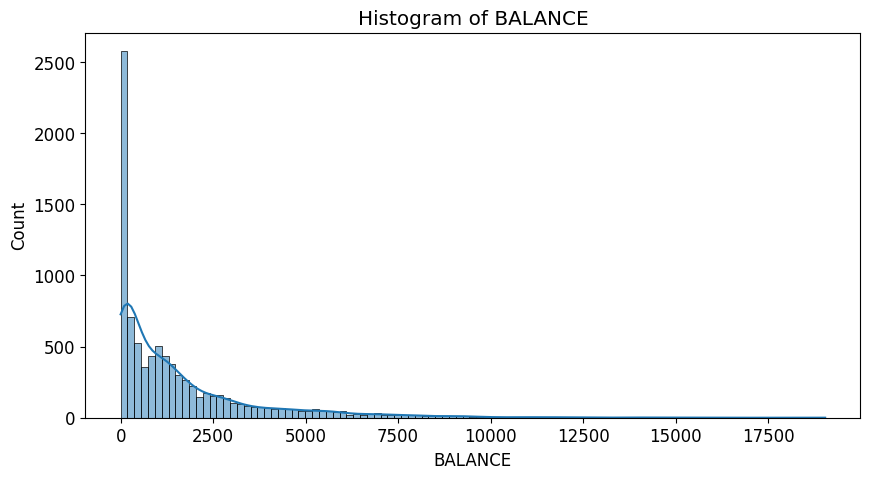

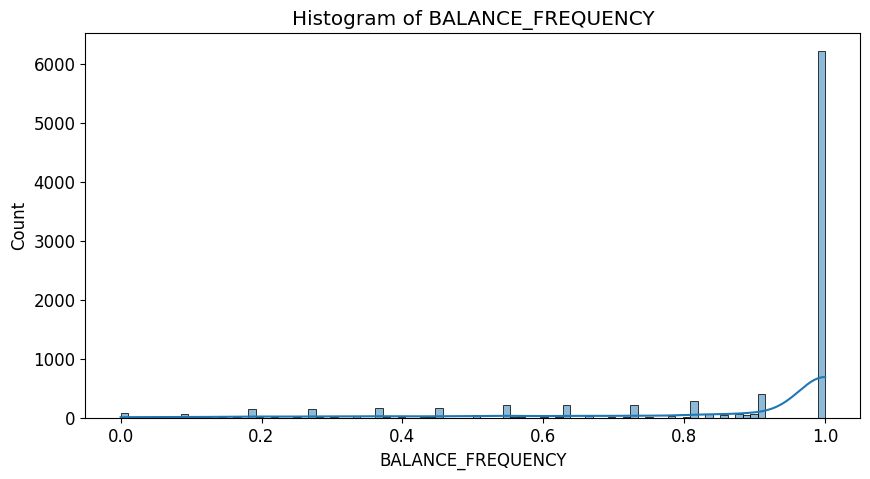

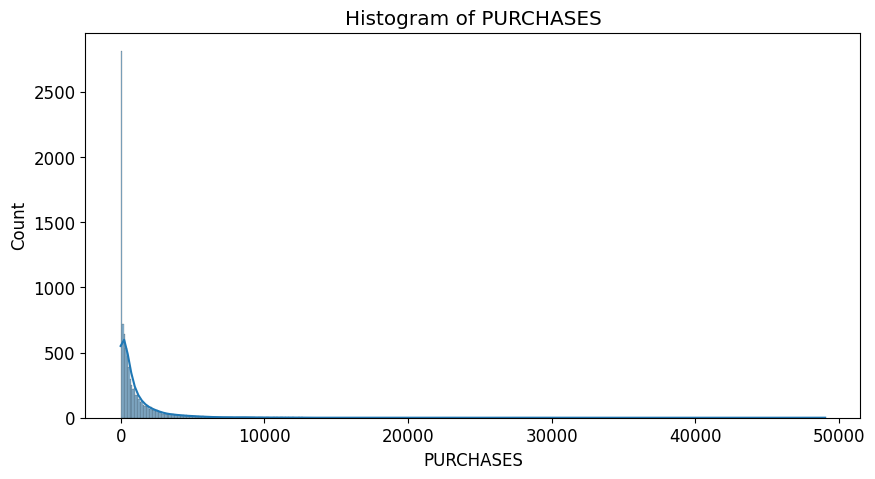

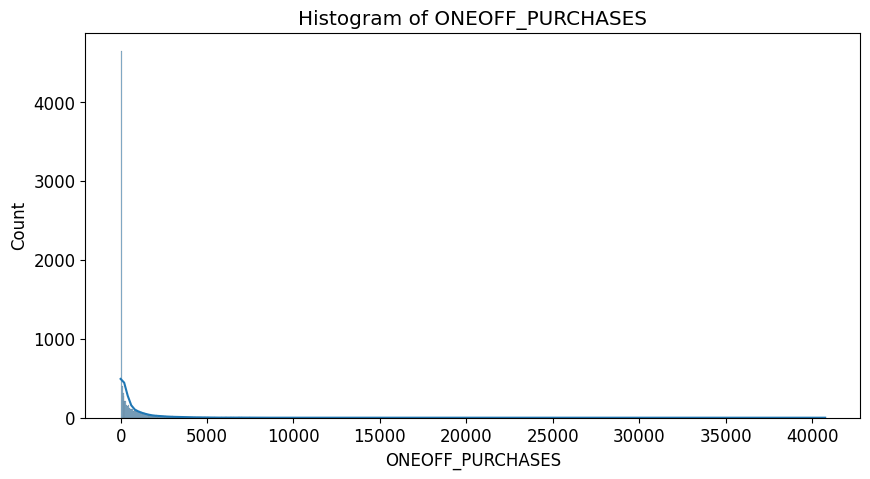

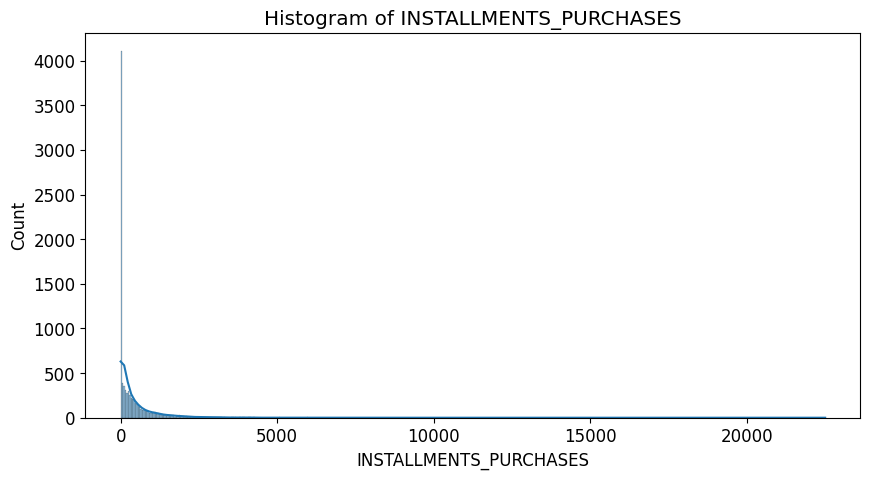

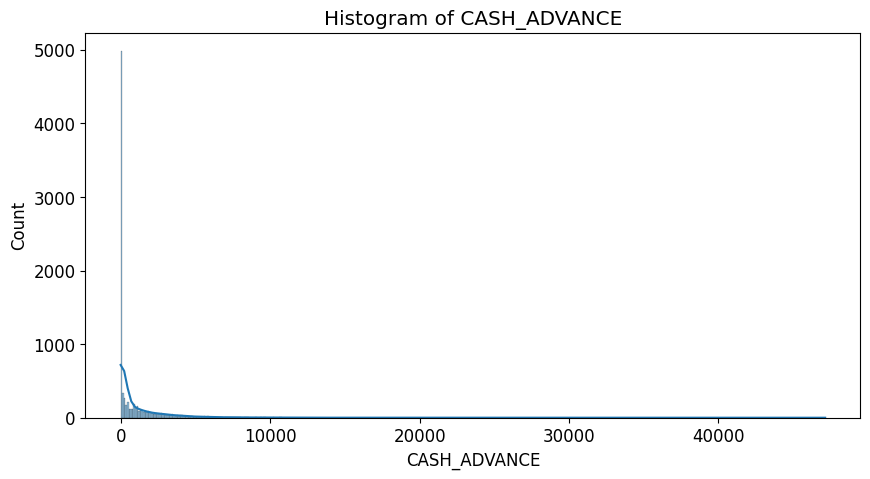

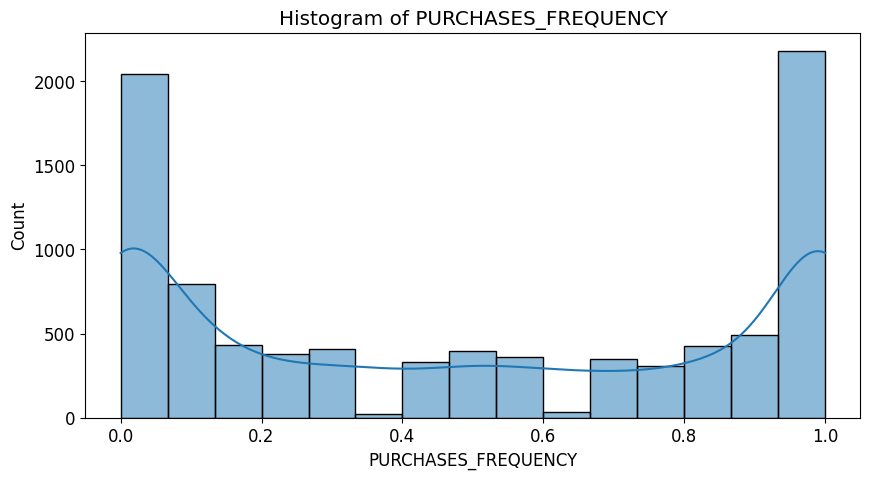

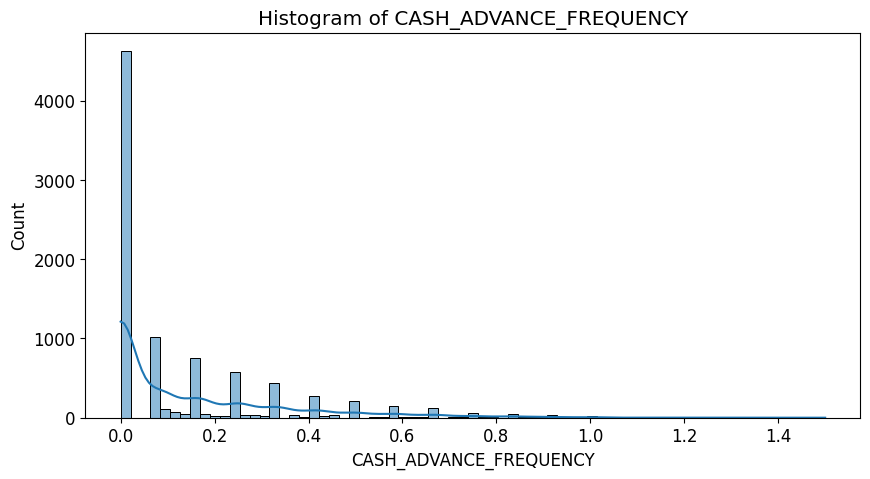

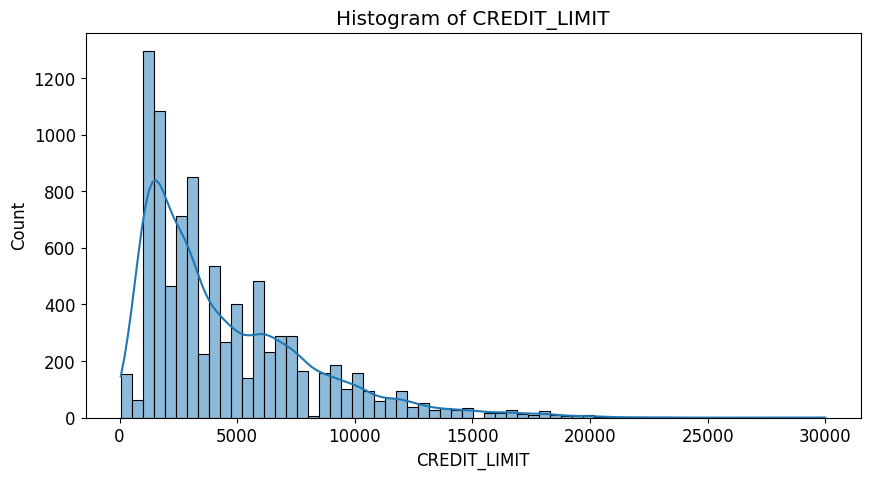

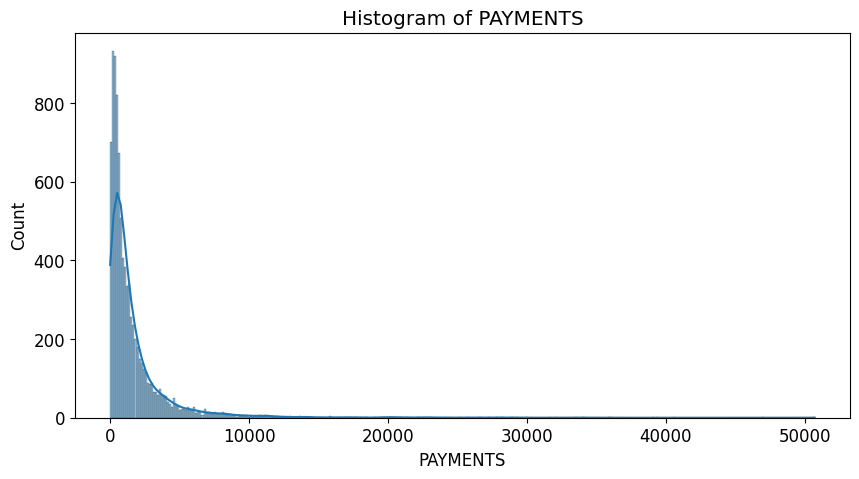

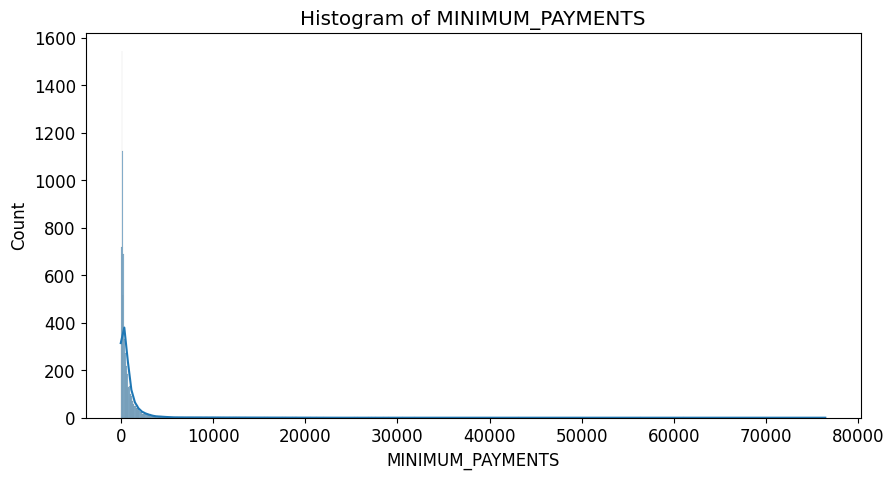

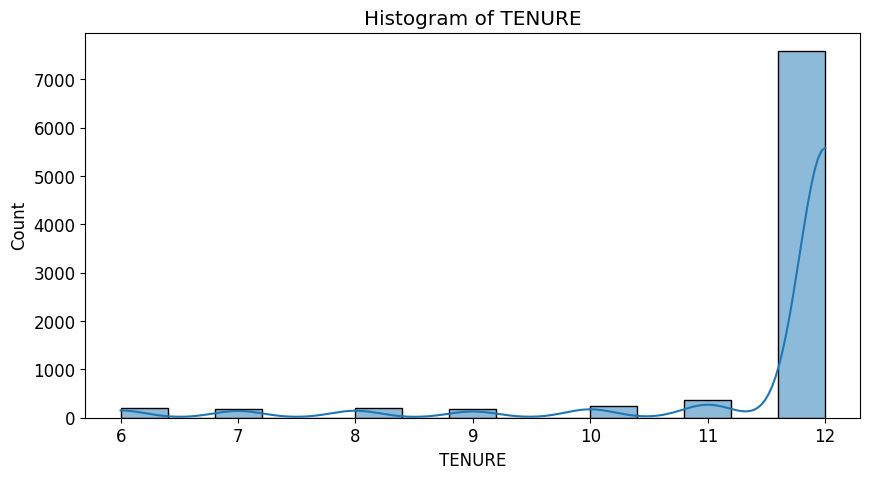

In [19]:
# Plot histograms for every feature (original values, before scaling)
for col in feature_cols:
    plt.figure()
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    sns.histplot(X[col], kde=True)
    plt.show()

3.2 Identify skewed financial features

In [20]:
# Skewness of each feature: close to 0 = symmetric, > 1 = strongly right skewed
skewness = X.skew().sort_values(ascending=False)
print("Skewness of features:")
display(skewness.to_frame('skewness'))

# Features with high skewness
skewed_features = skewness[skewness.abs() > 1].index.tolist()
print("Highly skewed features (|skew| > 1):", skewed_features)

Skewness of features:


,skewness
MINIMUM_PAYMENTS,13.852446
ONEOFF_PURCHASES,10.045083
PURCHASES,8.144269
INSTALLMENTS_PURCHASES,7.299120
PAYMENTS,5.907620
CASH_ADVANCE,5.166609
BALANCE,2.393386
CASH_ADVANCE_FREQUENCY,1.828686
CREDIT_LIMIT,1.522636
PURCHASES_FREQUENCY,0.060164


Highly skewed features (|skew| > 1): ['MINIMUM_PAYMENTS', 'ONEOFF_PURCHASES', 'PURCHASES', 'INSTALLMENTS_PURCHASES', 'PAYMENTS', 'CASH_ADVANCE', 'BALANCE', 'CASH_ADVANCE_FREQUENCY', 'CREDIT_LIMIT', 'BALANCE_FREQUENCY', 'TENURE']


3.3 Visualize pairwise relationships between spending variables

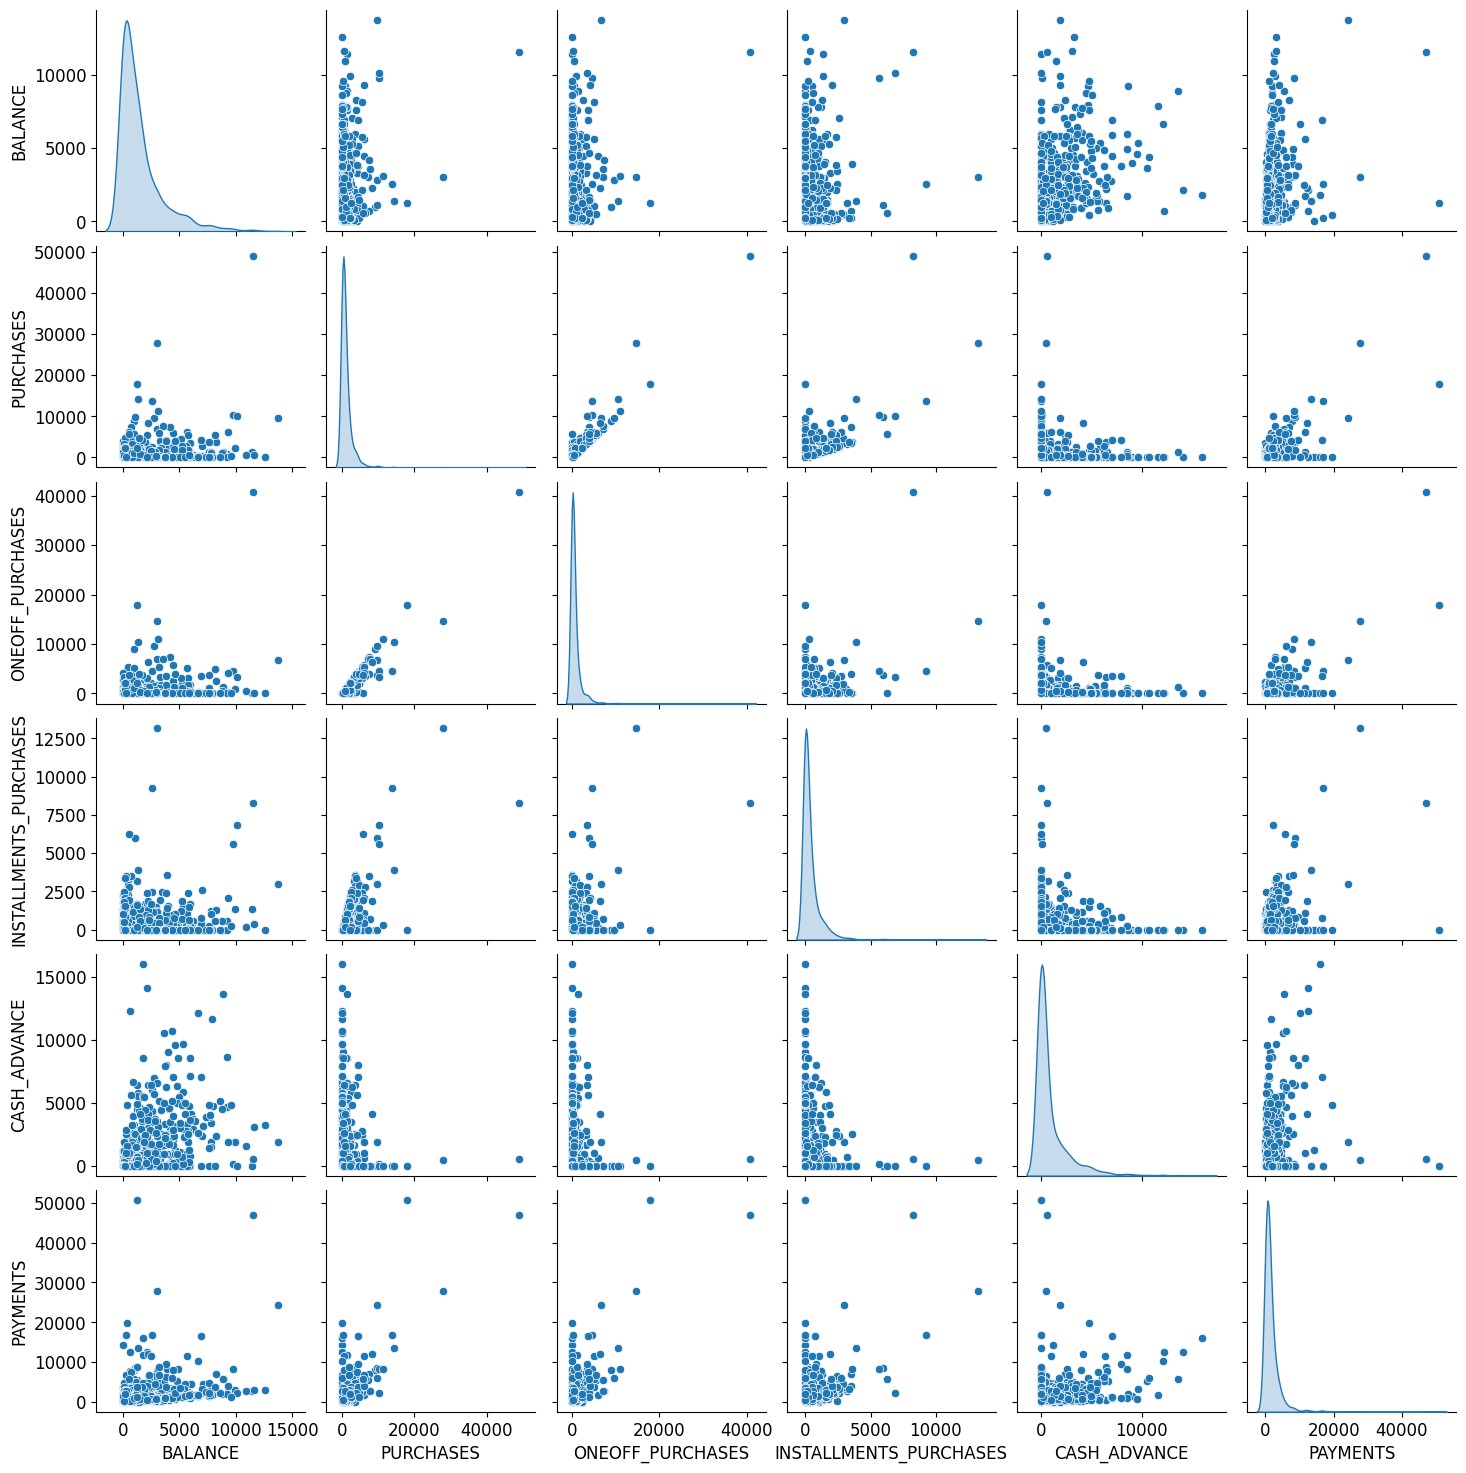

In [21]:
# Spending related variables only (all 12 would be too many plots)
spending_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PAYMENTS']

# Use a random sample of 1000 rows so pairplot runs faster
sns.pairplot(X[spending_cols].sample(1000, random_state=RANDOM_STATE), diag_kind='kde')
plt.show()

3.4 Detect potential outliers in customer behavior

In [22]:
# Detect outliers using IQR and Z-score

def detect_outliers_iqr(series, k=1.5):
    """Return boolean mask marking outliers using IQR."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    return (series < lower) | (series > upper)

def detect_outliers_zscore(series, thresh=3.0):
    """Return boolean mask marking outliers using z-score."""
    z = np.abs(stats.zscore(series))
    return pd.Series(z > thresh, index=series.index)

# Apply outlier detection to every feature
outlier_report = {}
for col in feature_cols:
    outlier_report[col] = {
        'iqr_count': int(detect_outliers_iqr(X[col]).sum()),
        'zscore_count': int(detect_outliers_zscore(X[col]).sum())
    }

print("Outlier summary (counts per column):")
display(pd.DataFrame(outlier_report).T)

Outlier summary (counts per column):


,iqr_count,zscore_count
BALANCE,695,196
BALANCE_FREQUENCY,1493,176
PURCHASES,808,135
ONEOFF_PURCHASES,1013,122
INSTALLMENTS_PURCHASES,867,137
CASH_ADVANCE,1030,182
PURCHASES_FREQUENCY,0,0
CASH_ADVANCE_FREQUENCY,525,199
CREDIT_LIMIT,248,152
PAYMENTS,808,159


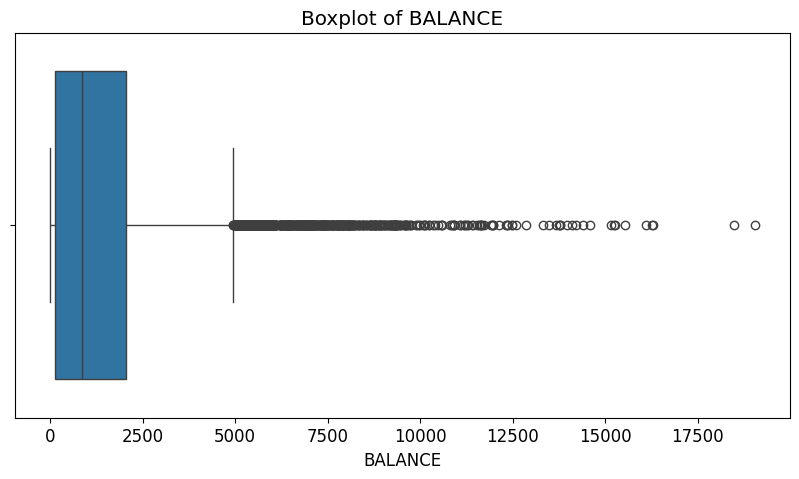

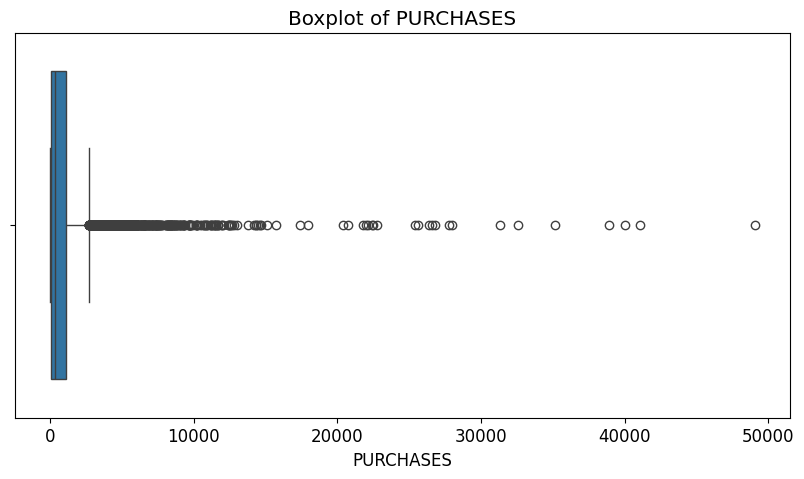

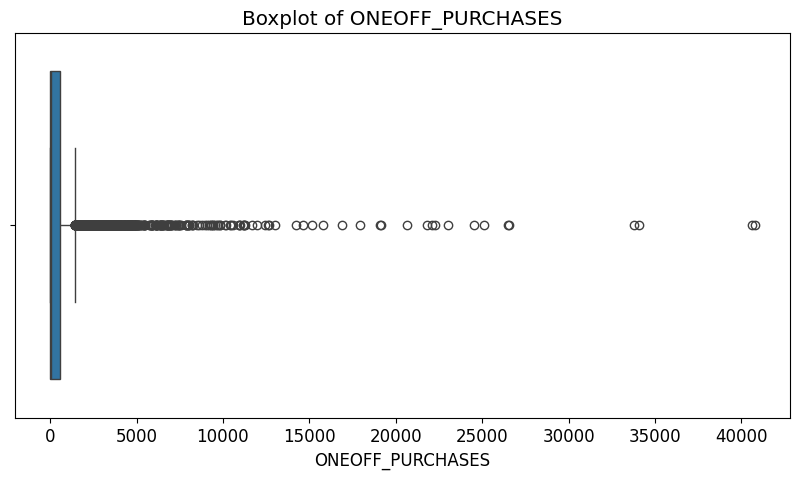

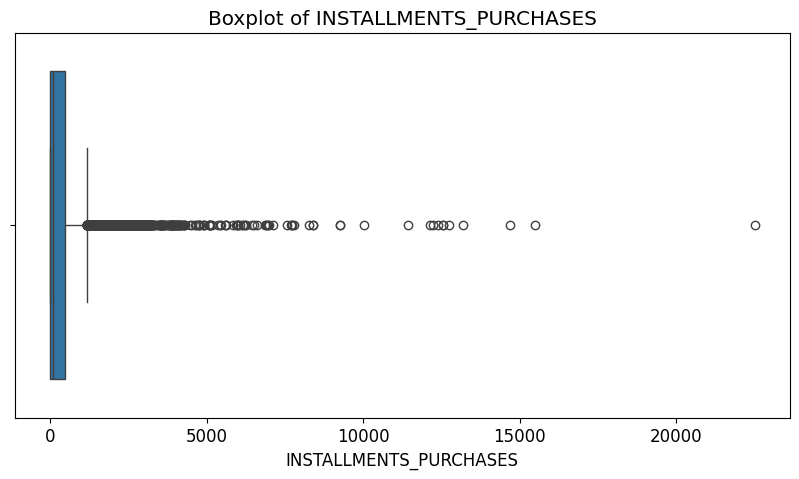

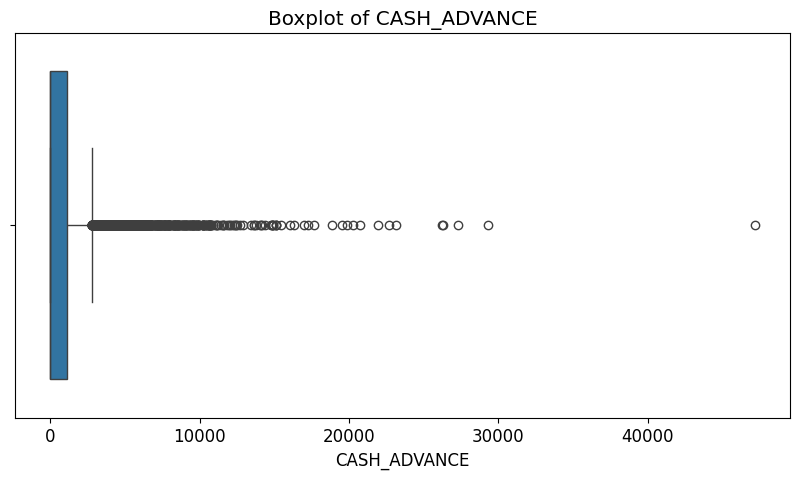

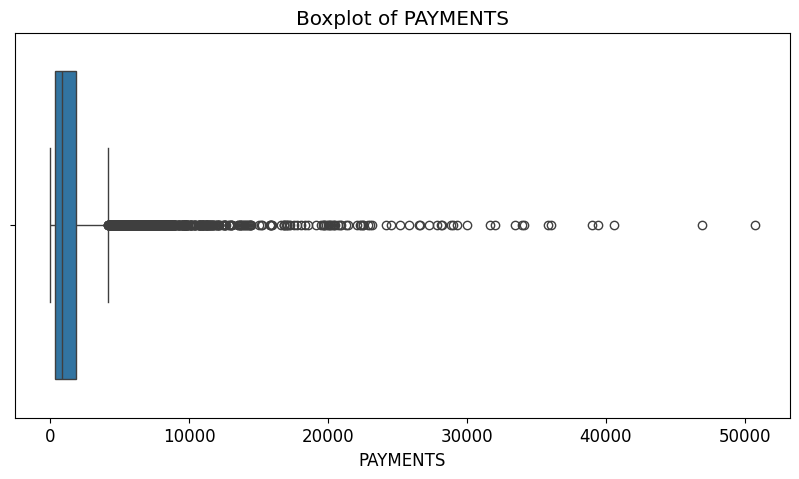

In [23]:
# boxplot for spending variables
for col in spending_cols:
    plt.figure()
    plt.title(f"Boxplot of {col}")
    sns.boxplot(x=X[col])
    plt.show()

Step 4: K-Means Clustering

4.1 Apply K-Means clustering

In [24]:
# First try K-Means with a random K = 3 just to see how it works
kmeans_test = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
test_labels = kmeans_test.fit_predict(X_scaled)

print("Cluster sizes for K=3:")
print(pd.Series(test_labels).value_counts().sort_index())
print("Inertia:", kmeans_test.inertia_)

Cluster sizes for K=3:
0    1588
1    6901
2     461
Name: count, dtype: int64
Inertia: 78611.9200580852


4.2 Determine optimal number of clusters (Elbow Method and Silhouette Score)

In [25]:
# Try K from 2 to 10 and save inertia and silhouette score for each
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    print(f"K={k}  inertia={km.inertia_:.2f}  silhouette={sil_scores[-1]:.4f}")

K=2  inertia=90244.19  silhouette=0.3901
K=3  inertia=78611.92  silhouette=0.3231
K=4  inertia=69770.69  silhouette=0.1907
K=5  inertia=63162.35  silhouette=0.2129
K=6  inertia=57071.10  silhouette=0.2422
K=7  inertia=51449.16  silhouette=0.2470
K=8  inertia=46809.02  silhouette=0.2531
K=9  inertia=43824.80  silhouette=0.2521
K=10  inertia=41562.07  silhouette=0.2404


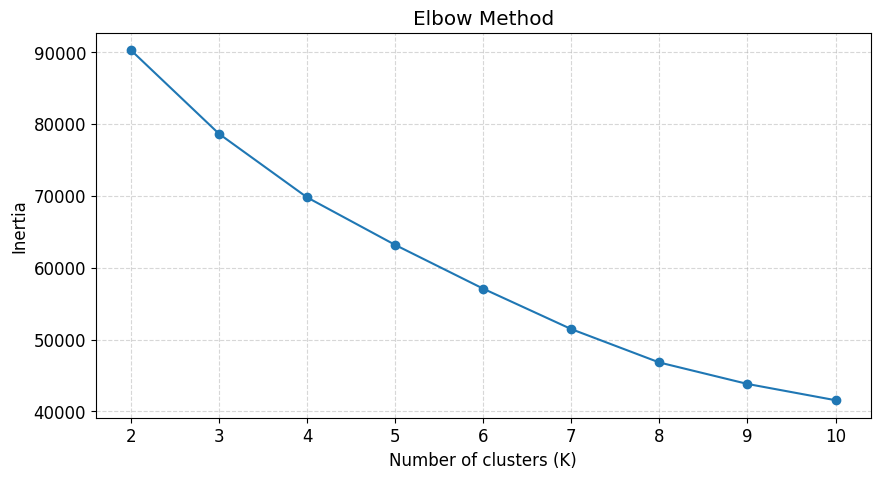

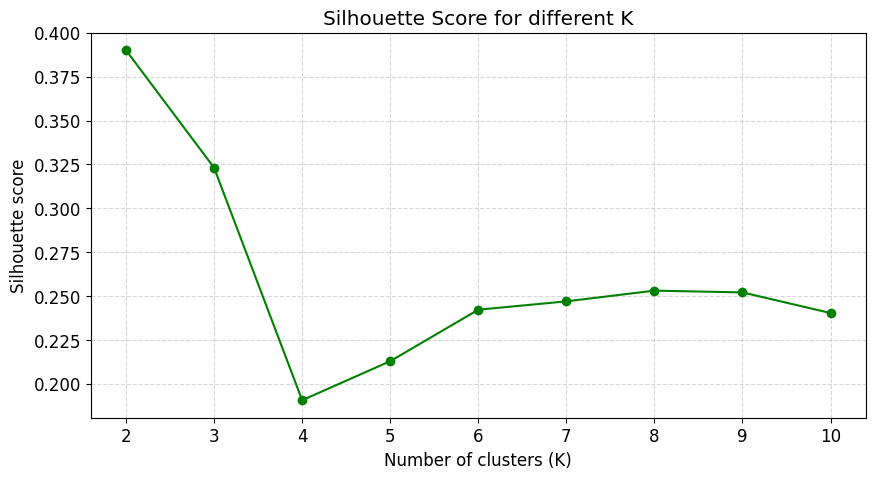

Optimal K (highest silhouette): 2


In [26]:
# Elbow method plot: look for the point where the curve starts to bend
plt.figure()
plt.plot(list(k_range), inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Silhouette score plot: higher is better
plt.figure()
plt.plot(list(k_range), sil_scores, marker='o', color='green')
plt.title("Silhouette Score for different K")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# K with the highest silhouette score
optimal_k = list(k_range)[int(np.argmax(sil_scores))]
print("Optimal K (highest silhouette):", optimal_k)
# you can also set optimal_k manually after looking at the elbow plot, for example optimal_k = 4

4.3 Train K-Means with optimal K

In [27]:
# Train final K-Means model
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
kmeans.fit(X_scaled)
print("Final model trained with K =", optimal_k)
print("Silhouette score:", silhouette_score(X_scaled, kmeans.labels_))

Final model trained with K = 2
Silhouette score: 0.3900983872788262


4.4 Assign cluster labels

In [28]:
# Add cluster labels to the dataframe
df_clean['KMeans_Cluster'] = kmeans.labels_

print("Number of customers in each cluster:")
display(df_clean['KMeans_Cluster'].value_counts().sort_index().to_frame('count'))
display(df_clean[['CUST_ID', 'KMeans_Cluster']].head(10))

Number of customers in each cluster:


,count
KMeans_Cluster,
0,1526
1,7424


,CUST_ID,KMeans_Cluster
0,C10001,1
1,C10002,0
2,C10003,1
3,C10004,1
4,C10005,1
5,C10006,1
6,C10007,0
7,C10008,1
8,C10009,1
9,C10010,1


4.5 Interpret cluster centroids

Cluster centroids (original scale):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,TENURE
cluster,,,,,,,,,,,,
0,4724.70,0.97,2622.02,1709.68,912.82,3421.42,0.54,0.33,9104.65,4896.68,2357.64,11.69
1,914.38,0.86,670.20,362.61,307.85,476.41,0.48,0.10,3545.87,1082.37,533.72,11.48


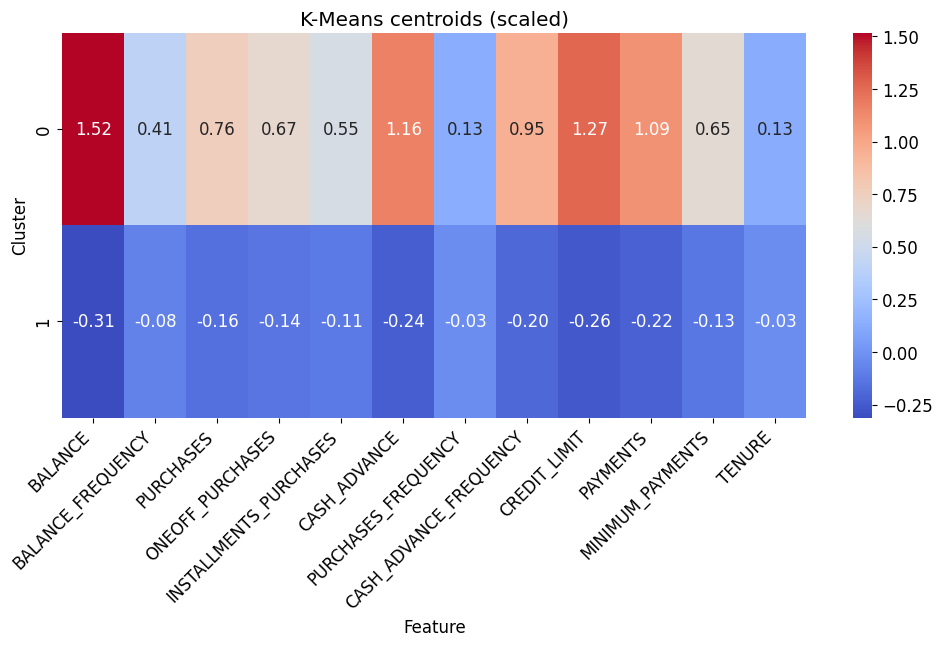

In [29]:
# Centroids are in scaled values, so convert them back to original values to read them easily
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
centroids_df = pd.DataFrame(centroids, columns=feature_cols)
centroids_df.index.name = 'cluster'
print("Cluster centroids (original scale):")
display(centroids_df.round(2))

# Heatmap of scaled centroids: shows which features are high/low in each cluster
plt.figure(figsize=(12, 5))
sns.heatmap(pd.DataFrame(kmeans.cluster_centers_, columns=feature_cols), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("K-Means centroids (scaled)")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.xticks(rotation=45, ha='right')
plt.show()

Step 5: Hierarchical Clustering

5.1 Perform Agglomerative Clustering

In [30]:
# Agglomerative clustering with ward linkage and the same K as K-Means
agg = AgglomerativeClustering(n_clusters=optimal_k, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

print("Cluster sizes (ward):")
print(pd.Series(agg_labels).value_counts().sort_index())

Cluster sizes (ward):
0    1329
1    7621
Name: count, dtype: int64


5.2 Experiment with linkage methods (ward, average, complete)

In [31]:
# Compare linkage methods using silhouette score
linkage_methods = ['ward', 'average', 'complete']
linkage_results = {}

for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=optimal_k, linkage=method)
    labels = model.fit_predict(X_scaled)
    linkage_results[method] = {
        'silhouette': silhouette_score(X_scaled, labels),
        'smallest_cluster': int(pd.Series(labels).value_counts().min())
    }

print(f"Linkage comparison (n_clusters = {optimal_k}):")
display(pd.DataFrame(linkage_results).T)

Linkage comparison (n_clusters = 2):


,silhouette,smallest_cluster
ward,0.374853,1329.0
average,0.878662,1.0
complete,0.827656,20.0


5.3 Plot dendrogram

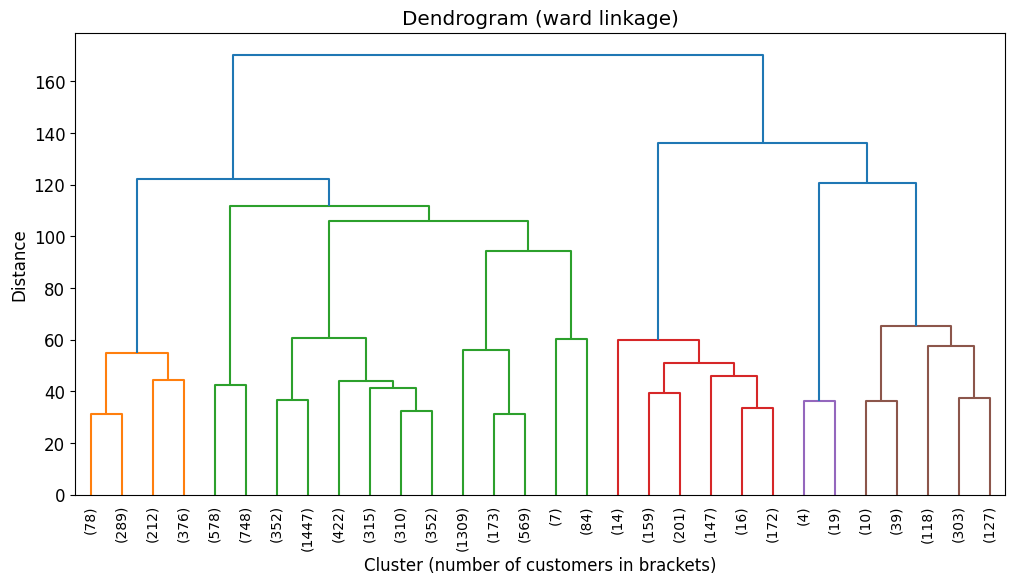

In [32]:
# Build the linkage matrix (ward) for the dendrogram
Z = linkage(X_scaled, method='ward')

# Show only the last 30 merged clusters, otherwise 8950 leaves are unreadable
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90., leaf_font_size=10)
plt.title("Dendrogram (ward linkage)")
plt.xlabel("Cluster (number of customers in brackets)")
plt.ylabel("Distance")
plt.show()

5.4 Determine optimal number of clusters

K=2  silhouette=0.3749
K=3  silhouette=0.3602
K=4  silhouette=0.2638
K=5  silhouette=0.2653
K=6  silhouette=0.1860
K=7  silhouette=0.1935
K=8  silhouette=0.1917
K=9  silhouette=0.1937
K=10  silhouette=0.1554


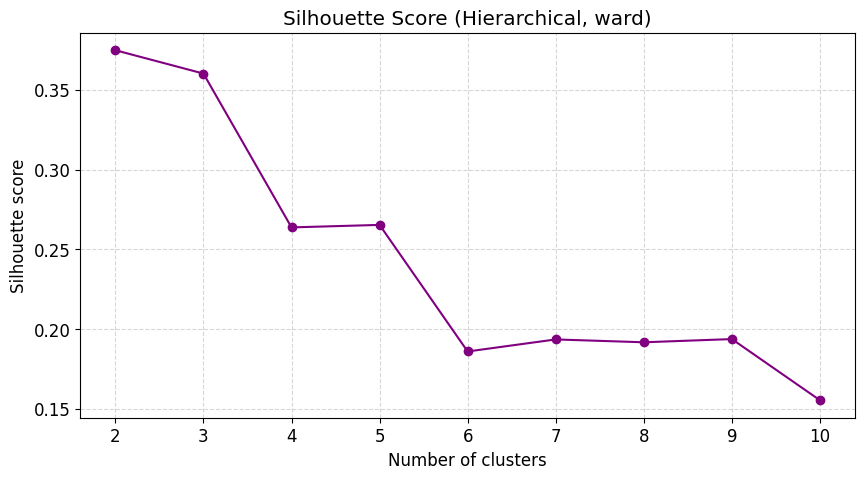

Optimal number of clusters (hierarchical): 2


In [33]:
# Silhouette score for different number of clusters using ward linkage
hc_sil = []
for k in range(2, 11):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    hc_sil.append(silhouette_score(X_scaled, labels))
    print(f"K={k}  silhouette={hc_sil[-1]:.4f}")

plt.figure()
plt.plot(range(2, 11), hc_sil, marker='o', color='purple')
plt.title("Silhouette Score (Hierarchical, ward)")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

hc_optimal_k = list(range(2, 11))[int(np.argmax(hc_sil))]
print("Optimal number of clusters (hierarchical):", hc_optimal_k)

In [34]:
# Final hierarchical model
hc = AgglomerativeClustering(n_clusters=hc_optimal_k, linkage='ward')
df_clean['HC_Cluster'] = hc.fit_predict(X_scaled)

print("Number of customers in each cluster:")
display(df_clean['HC_Cluster'].value_counts().sort_index().to_frame('count'))

Number of customers in each cluster:


,count
HC_Cluster,
0,1329
1,7621


5.5 Compare results with K-Means

In [35]:
# Silhouette score of both methods
km_sil = silhouette_score(X_scaled, df_clean['KMeans_Cluster'])
hc_sil_final = silhouette_score(X_scaled, df_clean['HC_Cluster'])
print(f"K-Means      (K={optimal_k}) silhouette: {km_sil:.4f}")
print(f"Hierarchical (K={hc_optimal_k}) silhouette: {hc_sil_final:.4f}")

# Adjusted Rand Index: 1 = same clusters, 0 = random agreement
ari = adjusted_rand_score(df_clean['KMeans_Cluster'], df_clean['HC_Cluster'])
print(f"Adjusted Rand Index between the two: {ari:.4f}")

# Crosstab: how customers of each K-Means cluster are distributed in hierarchical clusters
print("\nK-Means (rows) vs Hierarchical (columns):")
display(pd.crosstab(df_clean['KMeans_Cluster'], df_clean['HC_Cluster']))

# Mean of features in each hierarchical cluster (to compare with K-Means centroids)
print("\nHierarchical cluster means (original scale):")
display(df_clean.groupby('HC_Cluster')[feature_cols].mean().round(2))

K-Means      (K=2) silhouette: 0.3901
Hierarchical (K=2) silhouette: 0.3749
Adjusted Rand Index between the two: 0.6085

K-Means (rows) vs Hierarchical (columns):


HC_Cluster,0,1
KMeans_Cluster,,
0,1052,474
1,277,7147



Hierarchical cluster means (original scale):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,TENURE
HC_Cluster,,,,,,,,,,,,
0,4117.81,0.97,3258.83,1994.16,1265.19,3047.06,0.64,0.27,8954.78,5450.28,1661.74,11.88
1,1119.21,0.86,609.85,348.00,262.12,618.21,0.46,0.11,3716.43,1084.93,702.46,11.45
